In [12]:
import pandas as pd
import polars as pl

import glob
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.neighbors import NearestNeighbors

from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.metrics import adjusted_rand_score, silhouette_score

from scipy.ndimage import minimum_filter1d, maximum_filter1d

from kneed import KneeLocator

warnings.filterwarnings('ignore')

%matplotlib inline

In [13]:
files = sorted(glob.glob('./data/Daten/EV__*.parquet'))

lf = pl.scan_parquet(files)
schema = lf.collect_schema()

lf.head(10).collect()

Time,[29:0]Schweißmaschine - Einspeisung L1 Strom Istwert,[29:1]Schweißmaschine - Einspeisung L2 Strom Istwert,[29:2]Schweißmaschine - Einspeisung L3 Strom Istwert,[29:3]Schweißmaschine - Einspeisung L1 Spannung Istwert,[29:4]Schweißmaschine - Einspeisung L2 Spannung Istwert,[29:5]Schweißmaschine - Einspeisung L3 Spannung Istwert,[29:6]Schweißmaschine - Schweißspannung Istwert,[29:7]Schweißmaschine - Schweißstrom Istwert,[68:0]Schweißstrom Differenz HKS - Shunt,[68_101]Schweißmaschine - (+NS01 & +NS02) Schweißen ein LM (A12_5),[68_120]Schweißmaschine - (SA) Geschweißt Relais (A15_0),[68_694]Schweißmaschine - Glaettrolle ist auf SBE (E37_6),[68_695]Schweißmaschine - Glaettrolle ist ab SE (E37_7),[72:0]MP377: Schweißstrom Sollwert (DB21_DBW646),[72:1]MP377: Schweißkraft Sollwert (DB21_DBW642),[72:2]MP377: Glättkraft Sollwert (DB21_DBW654),[72:3]MP377: Schweißgeschwindigkeit Sollwert (DB21_DBW644),[72:46]S7-Schweißmaschine - Antrieb C-Wagen Istposition in mm (DB40_DBD32),[72:47]S7-Schweißmaschine - Antrieb C-Wagen V-Ist in mm/s (DB40_DBD36),[72:54]Schweißstromregelung: Temperatur Stromschiene oben (DB510_DBD4),[72:61]Schweißstromregelung: Schweißstrom Sollwert skaliert (DB510_DBD8),[72:62]Schweißstromregelung: Temperatur Start Schweißen (DB510_DBD40),[72:67]Schweißstromregelung: Reglerausgang (DB510_DBD28),[72:68]Schweißstromregelung: Reglerdifferenz (DB510_DBD16),[72:69]Schweißstromregelung: Spannung am Shunt Rückführung (DB510_DBD48),[72:70]Schweißstrom_HKS Zuführung (DB550_DBD0),[72:71]Schweißspannung_HKS (DB550_DBD4),[72:72]Schweißstrom_HKS Rückführung (DB550_DBD24),[72:73]Glättdruckregelung: Druckistwert Glättrollen (100%=50KN) (DB520_DBD0),[72:74]Glättdruckregelung: Drucksollwert Glättrollen (100%=40KN) (DB520_DBD8),[72:75]Glättdruckregelung: Drucksollwert Glättrollen HLG (100%=40KN) (DB520_DBD12),[72:78]Glättdruckregelung: Reglerausgang (DB520_DBD28),[72:79]Glättdruckregelung: Reglerdifferenz (DB520_DBD16),[72:81]Glättdruckregelung: Reglerausgang Prop_-Ventil normiert (MW2416/PEW156),[72:99]S7-Schweißmaschine - Sollwert Schweißrollendruck an Druckregelventil (DB550_DBD20),[72:100]S7-Schweißmaschine - Istwert Schweißrollendruck vom Druckregelventil (DB550_DBD8),[72:101]S7-Schweißmaschine - Istwert Luftdruck am Schweißrollenzylinder (DB550_DBD12),[72:102]S7-Schweißmaschine - Istwert Luftdruck am Netz (DB550_DBD16),[72:103]S7-Schweißmaschine - Schweißstromregelung Grundsollwert vom Regler (DB22_DBD20),[72:104]S7-Schweißmaschine - Schweißstromregelung I-Anteil vom Regler (DB22_DBD24),[72:105]S7-Schweißmaschine - Schweißstromregelung P-Anteil vom Regler (DB22_DBD0),[72:159]S7-Schweißmaschine - Tischverstellung Überlapptisch Ausspannlänge Sollwert (DB14_DBD4),[72:160]S7-Schweißmaschine - Tischverstellung Überlapptisch Ausspannlänge Istwert (DB14_DBD8),[72:162]S7-Schweißmaschine - Tischverstellung Überlapptisch Überlappung Sollwert (DB14_DBD24),[72:163]S7-Schweißmaschine - Tischverstellung Überlapptisch Überlappung Istwert (DB14_DBD28),[72:165]S7-Schweißmaschine - Tischverstellung Kipptisch Ausspannlänge Sollwert (DB13_DBD4),[72:166]S7-Schweißmaschine - Tischverstellung Kipptisch Ausspannlänge Istwert (DB13_DBD8),[72:168]S7-Schweißmaschine - Tischverstellung Überlapptisch Schränkung Sollwert (DB14_DBD44),[72:169]S7-Schweißmaschine - Tischverstellung Überlapptisch Schränkung Istwert (DB14_DBD48),"[72:214]S7-Schweißmaschine - Dicke Band Auslauf (0,4mm-2,5mm = 40-250) (DB268_DBW56)",[72:215]S7-Schweißmaschine - Materialnummer Band Auslauf (1-5) (DB268_DBW58),[72:216]S7-Schweißmaschine - Breite Band Auslauf (120mm-2000mm) (DB268_DBW60),[72:217]S7-Schweißmaschine - Kohlenstoffgehalt Band Auslauf (DB268_DBD62),"[72:220]S7-Schweißmaschine - Dicke Band Einlauf (0,4mm-2,5mm = 40-250) (DB268_DBW76)",[72:221]S7-Schweißmaschine - Materialnummer Band Einlauf (1-5) (DB268_DBW78),[72:222]S7-Schweißmaschine - Breite Band Einlauf (120mm-2000mm) (DB268_DBW80),[72:223]S7-Schweißmaschine - Kohlenstoffgehalt Band Einlauf (DB268_DBD82),[72:226]S7-Schw

In [14]:
EIN = "[72_1]S7-Schweißmaschine - Schweißen EIN (M215_0)"

features = [col for col, dtype in schema.items() if col not in ("Time", EIN) and dtype.is_numeric()]

df_features = lf.select("Time", EIN, *features).drop_nulls(subset=["Time", EIN])
df_features = df_features.with_columns(seq_id=(pl.col(EIN) & ~pl.col(EIN).shift(fill_value=False)).cum_sum() - 1)
df_features = df_features.filter(pl.col(EIN)).select("Time", "seq_id", *features)

df_features.slice(18190, 10).collect(engine="streaming")

Time,seq_id,[29:0]Schweißmaschine - Einspeisung L1 Strom Istwert,[29:1]Schweißmaschine - Einspeisung L2 Strom Istwert,[29:2]Schweißmaschine - Einspeisung L3 Strom Istwert,[29:3]Schweißmaschine - Einspeisung L1 Spannung Istwert,[29:4]Schweißmaschine - Einspeisung L2 Spannung Istwert,[29:5]Schweißmaschine - Einspeisung L3 Spannung Istwert,[29:6]Schweißmaschine - Schweißspannung Istwert,[29:7]Schweißmaschine - Schweißstrom Istwert,[68:0]Schweißstrom Differenz HKS - Shunt,[72:0]MP377: Schweißstrom Sollwert (DB21_DBW646),[72:1]MP377: Schweißkraft Sollwert (DB21_DBW642),[72:2]MP377: Glättkraft Sollwert (DB21_DBW654),[72:3]MP377: Schweißgeschwindigkeit Sollwert (DB21_DBW644),[72:46]S7-Schweißmaschine - Antrieb C-Wagen Istposition in mm (DB40_DBD32),[72:47]S7-Schweißmaschine - Antrieb C-Wagen V-Ist in mm/s (DB40_DBD36),[72:54]Schweißstromregelung: Temperatur Stromschiene oben (DB510_DBD4),[72:61]Schweißstromregelung: Schweißstrom Sollwert skaliert (DB510_DBD8),[72:62]Schweißstromregelung: Temperatur Start Schweißen (DB510_DBD40),[72:67]Schweißstromregelung: Reglerausgang (DB510_DBD28),[72:68]Schweißstromregelung: Reglerdifferenz (DB510_DBD16),[72:69]Schweißstromregelung: Spannung am Shunt Rückführung (DB510_DBD48),[72:70]Schweißstrom_HKS Zuführung (DB550_DBD0),[72:71]Schweißspannung_HKS (DB550_DBD4),[72:72]Schweißstrom_HKS Rückführung (DB550_DBD24),[72:73]Glättdruckregelung: Druckistwert Glättrollen (100%=50KN) (DB520_DBD0),[72:74]Glättdruckregelung: Drucksollwert Glättrollen (100%=40KN) (DB520_DBD8),[72:75]Glättdruckregelung: Drucksollwert Glättrollen HLG (100%=40KN) (DB520_DBD12),[72:78]Glättdruckregelung: Reglerausgang (DB520_DBD28),[72:79]Glättdruckregelung: Reglerdifferenz (DB520_DBD16),[72:81]Glättdruckregelung: Reglerausgang Prop_-Ventil normiert (MW2416/PEW156),[72:99]S7-Schweißmaschine - Sollwert Schweißrollendruck an Druckregelventil (DB550_DBD20),[72:100]S7-Schweißmaschine - Istwert Schweißrollendruck vom Druckregelventil (DB550_DBD8),[72:101]S7-Schweißmaschine - Istwert Luftdruck am Schweißrollenzylinder (DB550_DBD12),[72:102]S7-Schweißmaschine - Istwert Luftdruck am Netz (DB550_DBD16),[72:103]S7-Schweißmaschine - Schweißstromregelung Grundsollwert vom Regler (DB22_DBD20),[72:104]S7-Schweißmaschine - Schweißstromregelung I-Anteil vom Regler (DB22_DBD24),[72:105]S7-Schweißmaschine - Schweißstromregelung P-Anteil vom Regler (DB22_DBD0),[72:159]S7-Schweißmaschine - Tischverstellung Überlapptisch Ausspannlänge Sollwert (DB14_DBD4),[72:160]S7-Schweißmaschine - Tischverstellung Überlapptisch Ausspannlänge Istwert (DB14_DBD8),[72:162]S7-Schweißmaschine - Tischverstellung Überlapptisch Überlappung Sollwert (DB14_DBD24),[72:163]S7-Schweißmaschine - Tischverstellung Überlapptisch Überlappung Istwert (DB14_DBD28),[72:165]S7-Schweißmaschine - Tischverstellung Kipptisch Ausspannlänge Sollwert (DB13_DBD4),[72:166]S7-Schweißmaschine - Tischverstellung Kipptisch Ausspannlänge Istwert (DB13_DBD8),[72:168]S7-Schweißmaschine - Tischverstellung Überlapptisch Schränkung Sollwert (DB14_DBD44),[72:169]S7-Schweißmaschine - Tischverstellung Überlapptisch Schränkung Istwert (DB14_DBD48),"[72:214]S7-Schweißmaschine - Dicke Band Auslauf (0,4mm-2,5mm = 40-250) (DB268_DBW56)",[72:215]S7-Schweißmaschine - Materialnummer Band Auslauf (1-5) (DB268_DBW58),[72:216]S7-Schweißmaschine - Breite Band Auslauf (120mm-2000mm) (DB268_DBW60),[72:217]S7-Schweißmaschine - Kohlenstoffgehalt Band Auslauf (DB268_DBD62),"[72:220]S7-Schweißmaschine - Dicke Band Einlauf (0,4mm-2,5mm = 40-250) (DB268_DBW76)",[72:221]S7-Schweißmaschine - Materialnummer Band Einlauf (1-5) (DB268_DBW78),[72:222]S7-Schweißmaschine - Breite Band Einlauf (120mm-2000mm) (DB268_DBW80),[72:223]S7-Schweißmaschine - Kohlenstoffgehalt Band Einlauf (DB268_DBD82),[72:226]S7-Schweißmaschine - Druckmessung Überlapptisch Hydraulikzylinder Kolbenseite (DB9_DBD60),[72:227]S7-Schweißmaschine - Druckmessung Überlapptisch Hydraulikzylinder Flächenseite (DB9_DBD64)
datetime[ms],u32,f32,f32,f32,f32,f32,f32,f32,f32,

In [15]:
means = df_features.select([pl.col(col).mean().alias(col) for col in features]).collect(engine="streaming")
stds = df_features.select([pl.col(col).std().alias(col) for col in features]).collect(engine="streaming")

means = np.array([means[col][0] for col in features])
stds = np.array([stds[col][0] for col in features])

means_np = np.asarray(means, dtype=np.float64)
stds_np = np.asarray(stds, dtype=np.float64)

summary = pl.DataFrame({
    "feature": features,
    "mean": means_np,
    "std": stds_np
})

const_features = (
    summary
    .filter(pl.col("std") == 0)
    .get_column("feature")
    .to_list()
    
)


valid = [i for i, col in enumerate(features) if col not in const_features]
means_np = means_np[valid]
stds_np = stds_np[valid]
features = [features[i] for i in valid]

df_features = lf.select("Time", EIN, *features).drop_nulls(subset=["Time", EIN])
df_features = df_features.with_columns(seq_id=(pl.col(EIN) & ~pl.col(EIN).shift(fill_value=False)).cum_sum() - 1)
df_features = df_features.filter(pl.col(EIN)).select("Time", "seq_id", *features)

In [16]:
df_seq = (
    df_features
    .group_by("seq_id")
    .agg(start=pl.col("Time").min(), end=pl.col("Time").max())
    .sort("seq_id")
    .collect(engine="streaming")
)

def interpolate(N):
    X = np.empty((len(df_seq), len(features) * N), dtype=np.float64)
    seq_ids = df_seq["seq_id"].to_list()
    norm = [((pl.col(col).cast(pl.Float64) - mean) / std).alias(col) for col, mean, std in zip(features, means_np, stds_np)]
    empty = []

    for i, row in enumerate(df_seq.iter_rows(named=True)):
        seq = lf.filter(pl.col("Time").is_between(row["start"], row["end"]))
        seq = seq.filter(pl.col(EIN))
        seq = seq.select("Time", *features)
        seq = seq.sort("Time")
        seq = seq.with_columns(norm)
        seq = seq.collect(engine="streaming")

        t = (seq["Time"] - seq["Time"][0]).dt.total_milliseconds().to_numpy()
        t_lin = np.linspace(0, t[-1], N)
        
        for j, feature in enumerate(features):
            y = seq[feature].to_numpy()
            
            dummy = np.isfinite(y)
            if not dummy.any():
                empty.append((row["seq_id"], feature))
                X[i, j*N:(j+1)*N] = 0.0
                continue
            X[i, j*N:(j+1)*N] = np.interp(t_lin, t[dummy], y[dummy])
    return X, seq_ids, empty

def build_df_X(N):
    X, seq_ids, _ = interpolate(N)

    cols = [
        f"{feature}_t_{i}"
        for feature in features
        for i in range(N)
    ]

    return pd.DataFrame(
        X,
        index=pd.Index(seq_ids, name="seq_id"),
        columns=cols,
    )

In [17]:
N_SAMPLES = 300

df_X = build_df_X(N_SAMPLES)
X = df_X.to_numpy()
df_X.iloc[:10, ::N_SAMPLES]

,[29:0]Schweißmaschine - Einspeisung L1 Strom Istwert_t_0,[29:1]Schweißmaschine - Einspeisung L2 Strom Istwert_t_0,[29:2]Schweißmaschine - Einspeisung L3 Strom Istwert_t_0,[29:3]Schweißmaschine - Einspeisung L1 Spannung Istwert_t_0,[29:4]Schweißmaschine - Einspeisung L2 Spannung Istwert_t_0,[29:5]Schweißmaschine - Einspeisung L3 Spannung Istwert_t_0,[29:6]Schweißmaschine - Schweißspannung Istwert_t_0,[29:7]Schweißmaschine - Schweißstrom Istwert_t_0,[68:0]Schweißstrom Differenz HKS - Shunt_t_0,[72:0]MP377: Schweißstrom Sollwert (DB21_DBW646)_t_0,...,"[72:214]S7-Schweißmaschine - Dicke Band Auslauf (0,4mm-2,5mm = 40-250) (DB268_DBW56)_t_0",[72:215]S7-Schweißmaschine - Materialnummer Band Auslauf (1-5) (DB268_DBW58)_t_0,[72:216]S7-Schweißmaschine - Breite Band Auslauf (120mm-2000mm) (DB268_DBW60)_t_0,[72:217]S7-Schweißmaschine - Kohlenstoffgehalt Band Auslauf (DB268_DBD62)_t_0,"[72:220]S7-Schweißmaschine - Dicke Band Einlauf (0,4mm-2,5mm = 40-250) (DB268_DBW76)_t_0",[72:221]S7-Schweißmaschine - Materialnummer Band Einlauf (1-5) (DB268_DBW78)_t_0,[72:222]S7-Schweißmaschine - Breite Band Einlauf (120mm-2000mm) (DB268_DBW80)_t_0,[72:223]S7-Schweißmaschine - Kohlenstoffgehalt Band Einlauf (DB268_DBD82)_t_0,[72:226]S7-Schweißmaschine - Druckmessung Überlapptisch Hydraulikzylinder Kolbenseite (DB9_DBD60)_t_0,[72:227]S7-Schweißmaschine - Druckmessung Überlapptisch Hydraulikzylinder Flächenseite (DB9_DBD64)_t_0
seq_id,,,,,,,,,,,,,,,,,,,,,
0,-1.297148,-1.268423,-1.268564,1.229979,1.184601,-0.035332,-1.096739,-1.284923,0.337652,-0.402192,...,-0.864620,1.992485,0.647726,-0.568662,-0.923870,-1.366042,-0.335156,0.458539,1.023532,2.539021
1,-1.289318,-1.268423,-1.268564,0.616856,1.376098,0.737376,-1.095343,-1.283809,0.342114,-1.210720,...,-0.949266,-1.328208,-0.331980,0.483010,-0.923870,-1.366042,-0.347407,0.458539,0.942850,1.303295
2,-1.281487,-1.268423,-1.268564,-0.173731,-1.303707,-1.130994,-1.093947,-1.279351,0.340260,-1.095216,...,-0.949266,-1.328208,-0.345043,0.483010,-0.854382,-1.366042,-1.078370,0.414097,0.942850,1.303295
3,-1.289318,-1.268423,-1.268564,1.264312,1.182075,-0.065774,-1.095343,-1.282694,0.342139,-1.095216,...,-0.878727,-1.328208,-1.124454,0.437285,-0.923870,0.422324,-1.482646,-0.563642,-0.106099,2.539021
4,-1.285403,-1.268423,-1.268564,-1.347086,-0.256905,1.066051,-1.092551,-1.281580,0.339785,-1.210720,...,-0.949266,0.332139,-1.555525,-0.568662,-0.923870,0.422324,-1.482646,-0.519199,0.135969,7.481921
5,-1.285403,-1.268423,-1.262809,0.225738,1.320532,1.097408,-1.091155,-1.283251,0.347560,-1.210720,...,-0.949266,0.332139,-1.555525,-0.522937,-0.923870,0.422324,-1.482646,-0.563642,3.040733,0.067570
6,-1.281487,-1.268423,-1.262809,-0.515902,0.893223,1.400220,-1.089061,-1.281023,0.346579,-1.210720,...,-0.949266,0.332139,-1.555525,-0.568662,-0.923870,0.422324,-1.482646,-0.563642,3.040733,1.303295
7,-1.289318,-1.268423,-1.262809,0.493211,1.388497,0.888210,-1.091853,-1.282137,0.342165,-1.210720,...,-0.949266,0.332139,-1.555525,-0.568662,-0.937768,0.422324,-1.482646,-0.563642,1.265593,1.303295
8,-1.281487,-1.268423,-1.262809,1.408372,0.369937,-0.996868,-1.093947,-1.279908,0.338049,-1.210720,...,-0.963374,0.332139,-1.555525,-0.568662,-0.923870,0.422324,-1.482646,-0.563642,0.700781,1.303295


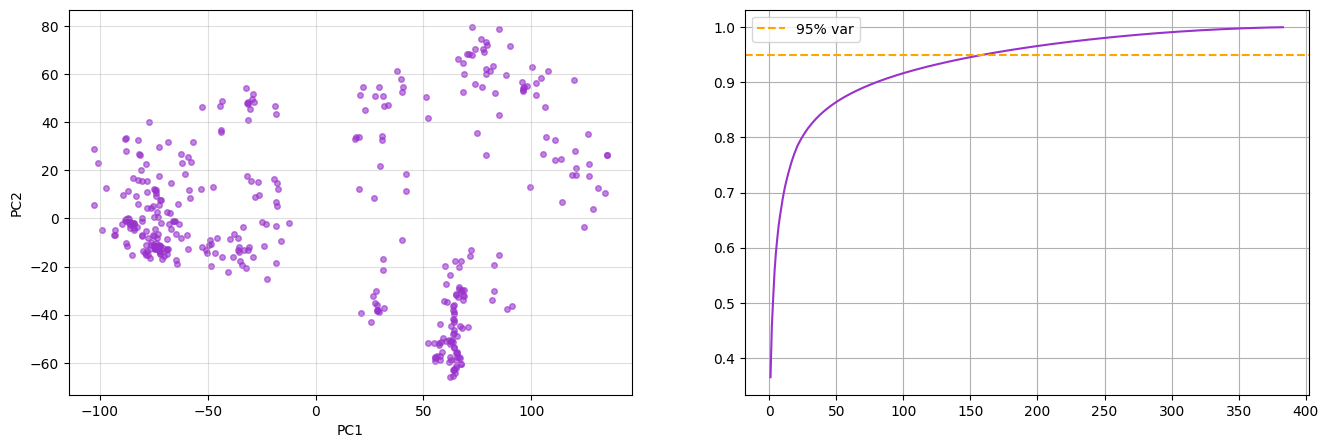

In [18]:
pca2 = PCA(n_components=2)

df_pca = pd.DataFrame(pca2.fit_transform(X), columns=["PC1", "PC2"], index=df_X.index)

plt.figure(figsize=(16, 5))
plt.subplot(121)
plt.scatter(df_pca["PC1"], df_pca["PC2"], s=16, alpha=0.6, color="darkorchid")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.grid(alpha=0.4)

plt.subplot(122)
PCA_ = PCA()
PCA_.fit(X)

cum_var = PCA_.explained_variance_ratio_.cumsum()

plt.plot(range(1, len(cum_var) + 1), cum_var, color="darkorchid")

plt.axhline(y=0.95, linestyle="--", label="95% var", color="orange")
plt.grid(True)
plt.legend()
plt.show()

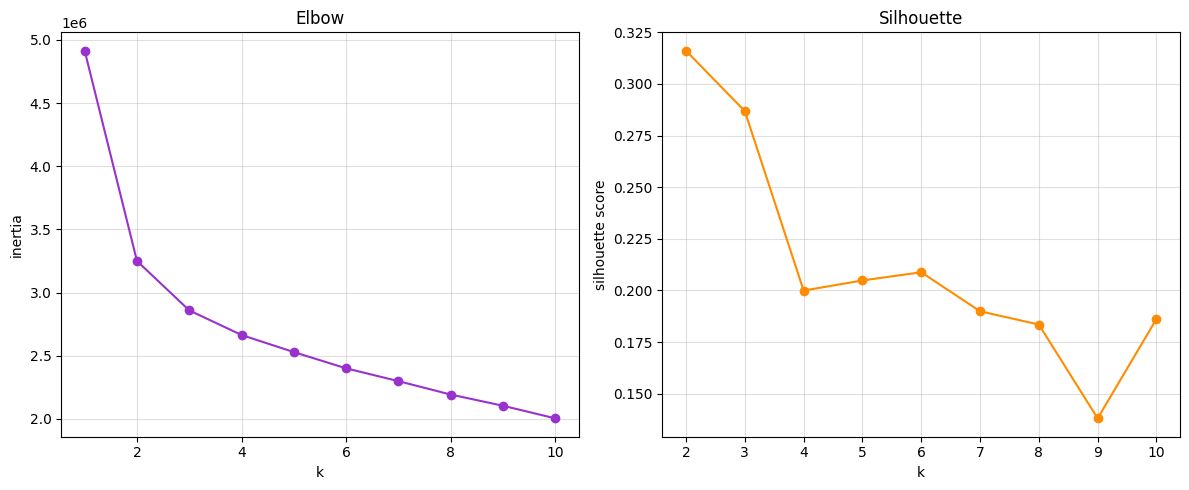

In [19]:
var = PCA_.explained_variance_ratio_

total = 0
n = 0

for v in var:
    total += v
    n += 1

    if  total >= 0.95:
        break
        
X_PCA = PCA_.transform(X)
X_reduced = X_PCA[:, :n]

def elbow(n_init, k_max=10, data=X_reduced):
    ks = np.arange(1,k_max+1)
    inertias = [KMeans(n_clusters=k, n_init=n_init, random_state=0).fit(data).inertia_ for k in ks]
    
    return ks, inertias

ks, inertias = elbow(n_init=50)
ret = np.array(inertias)

sil_ks = ks[1:]
sil = [silhouette_score(X_reduced, KMeans(n_clusters=k, n_init=50, random_state=0).fit_predict(X_reduced)) for k in sil_ks]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.plot(ks, ret, marker="o", color="darkorchid")
ax1.set_title("Elbow")
ax1.set_xlabel("k")
ax1.set_ylabel("inertia")
ax1.grid(alpha=0.4)

ax2.plot(sil_ks, sil, marker="o", color="darkorange")
ax2.set_title("Silhouette")
ax2.set_xlabel("k")
ax2.set_ylabel("silhouette score")
ax2.grid(alpha=0.4)

plt.tight_layout()
plt.show()

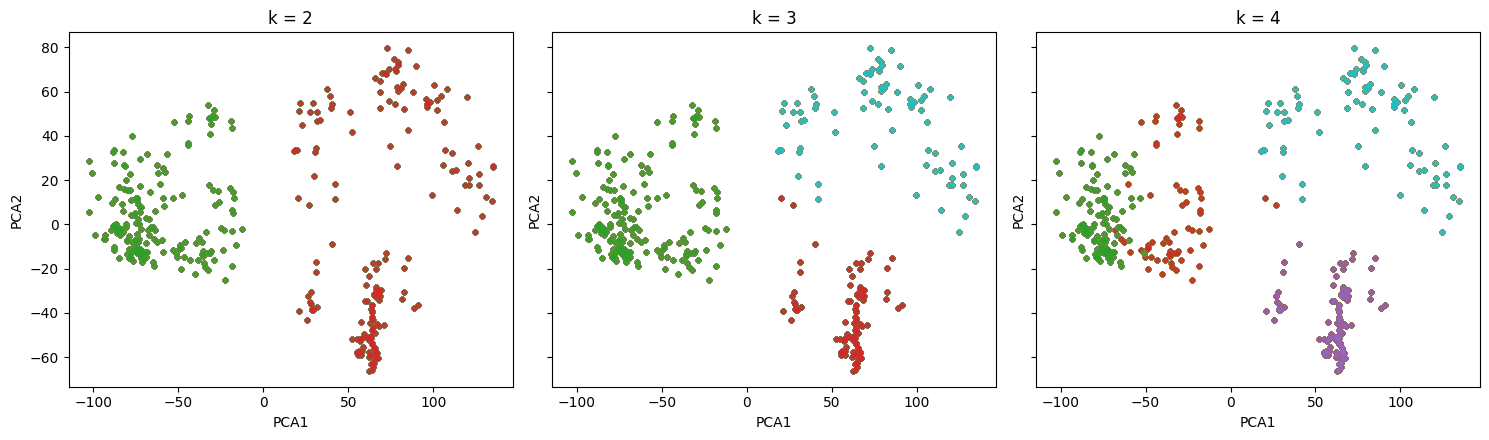

In [20]:
cluster_containers = []

for k in [2, 3, 4]:
    tmp = df_pca[["PC1", "PC2"]].copy()
    tmp["cluster"] = KMeans(n_clusters=k, n_init=50, random_state=0).fit_predict(X_reduced).astype(str)
    tmp["k"] = k
    cluster_containers.append(tmp)

main_container = pd.concat(cluster_containers)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True)

for ax, k in zip(axes, [2, 3, 4]):
    k_container = main_container[main_container["k"] == k]

    for cluster in k_container["cluster"]:
        cluster_data = k_container[k_container["cluster"] == cluster]
        ax.scatter(cluster_data["PC1"], cluster_data["PC2"], s=10, alpha=0.7)

    ax.set_title(f"k = {k}")
    ax.set_xlabel("PCA1")
    ax.set_ylabel("PCA2")

plt.tight_layout()
plt.show()

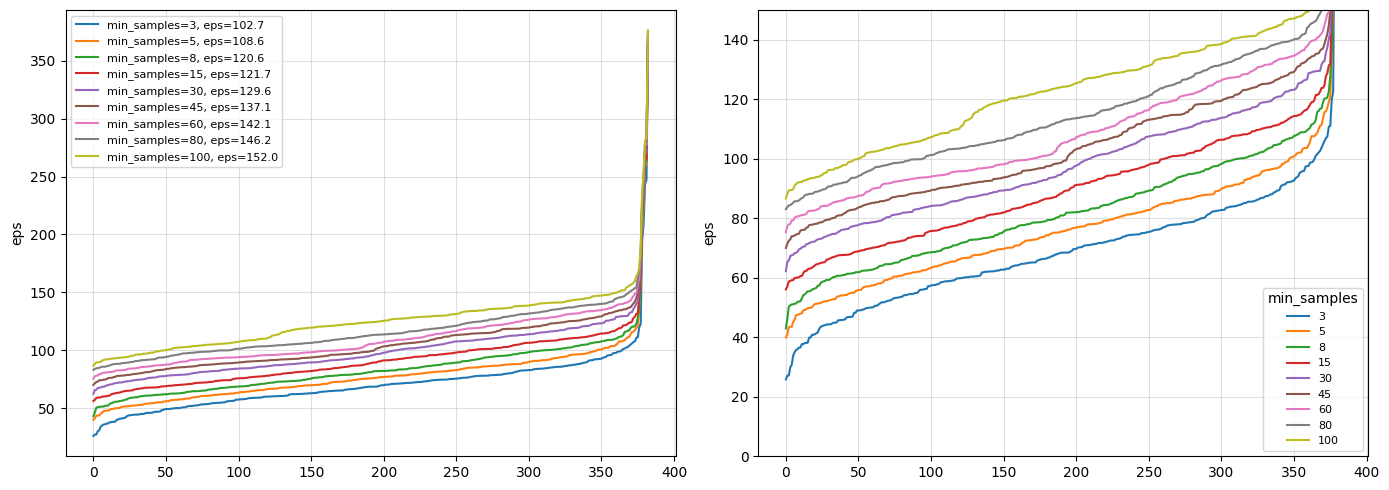

In [21]:
min_samples = [3, 5, 8, 15, 30, 45, 60, 80, 100]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
eps_per_ms = {}

for ms in min_samples:
    d, _ = NearestNeighbors(n_neighbors=ms).fit(X_reduced).kneighbors(X_reduced)
    kd = np.sort(d[:, -1]) # drop first zero columnn

    knee = KneeLocator(range(len(kd)), kd, curve="convex", direction="increasing").knee
    eps_per_ms[ms] = kd[knee]

    line, = ax1.plot(kd, label=f"min_samples={ms}, eps={kd[knee]:.1f}")
    ax2.plot(kd, color=line.get_color(), label=ms)

ax2.set_ylim(0, 150)

for ax in (ax1, ax2):
    ax.set_ylabel("eps")
    ax.grid(alpha=0.4)

ax1.legend(fontsize=8)
ax2.legend(title="min_samples", fontsize=8)

plt.tight_layout()
plt.show()

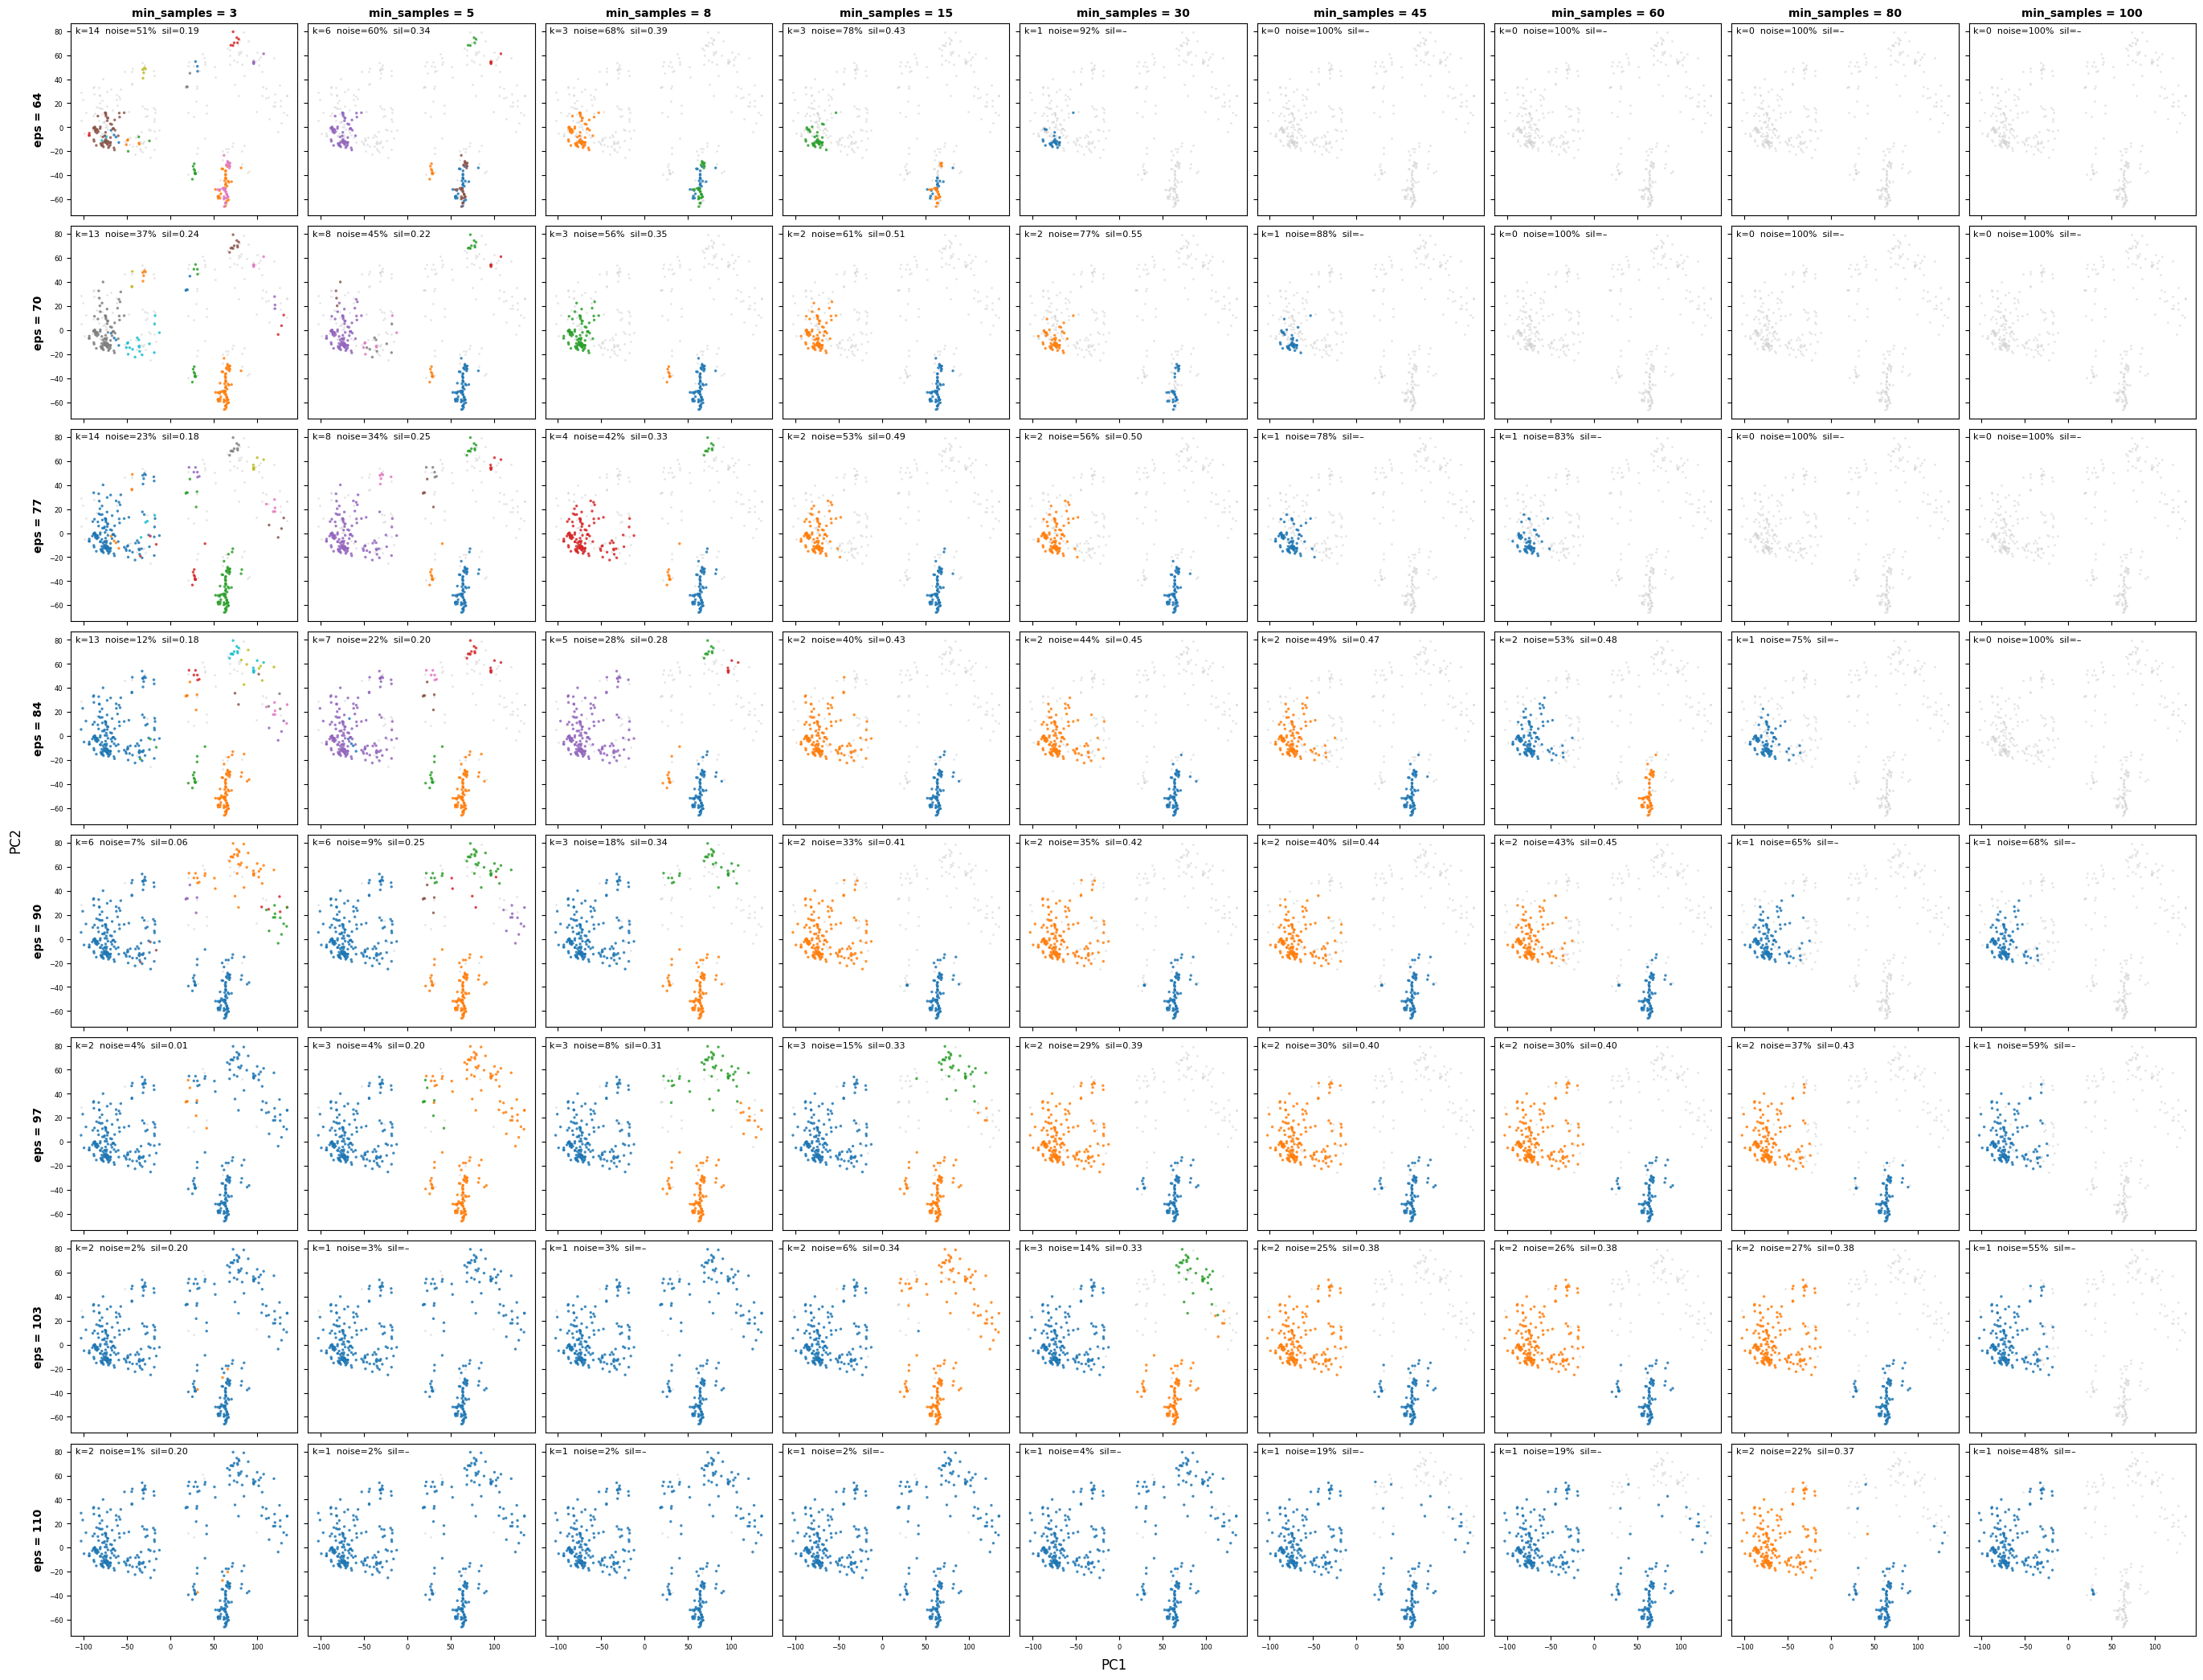

In [22]:
palette = plt.get_cmap("tab10").colors
eps_list = [64, 70, 77, 84, 90, 97, 103, 110]
ne, nm = len(eps_list), len(min_samples)
pca_c = df_pca.to_numpy()  # PC1/PC2 for the scatter plots

fig, axes = plt.subplots(ne, nm, figsize=(3 * nm, 2.6 * ne), sharex=True, sharey=True, squeeze=False, constrained_layout=True)

history = {"eps": [], "min_samples": [], "n_clusters": [], "noise": [], "silhouette": []}
for i, e in enumerate(eps_list):
    for j, ms in enumerate(min_samples):
        ax = axes[i, j]
        db = DBSCAN(eps=e, min_samples=ms).fit_predict(X_reduced)
        mask = db != -1
        n_cl = len(set(db[mask]))
        noise = (~mask).mean()
        sil = silhouette_score(X_reduced[mask], db[mask]) if n_cl >= 2 else np.nan
        history["eps"].append(e); history["min_samples"].append(ms)
        history["n_clusters"].append(n_cl); history["noise"].append(noise)
        history["silhouette"].append(sil)

        # noise first (background), clusters on top
        ax.scatter(*pca_c[~mask].T, c="lightgrey", s=4, alpha=0.6, linewidths=0)
        colors = [palette[k % len(palette)] for k in db[mask]]
        ax.scatter(*pca_c[mask].T, c=colors, s=6, alpha=0.85, linewidths=0)

        sil_txt = f"{sil:.2f}" if not np.isnan(sil) else "–"
        ax.text(0.02, 0.98, f"k={n_cl}  noise={noise:.0%}  sil={sil_txt}",
                transform=ax.transAxes, va="top", fontsize=8,
                bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.8))
        ax.tick_params(labelsize=6)

        if i == 0:      ax.set_title(f"min_samples = {ms}", fontsize=10, fontweight="bold")
        if j == 0:      ax.set_ylabel(f"eps = {e}", fontsize=10, fontweight="bold")

fig.supxlabel("PC1")
fig.supylabel("PC2", x=-0.01)
plt.show()

df_history = pd.DataFrame(history)

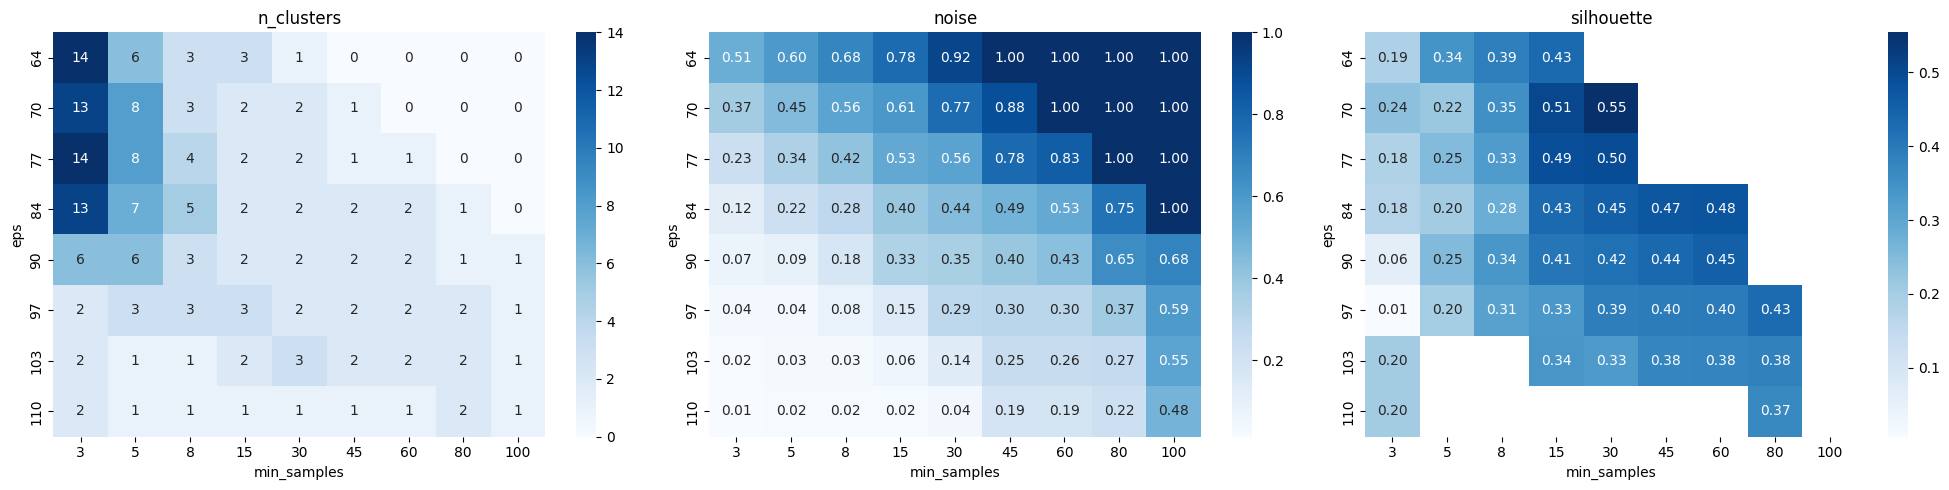

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for ax, col in zip(axes, ["n_clusters", "noise", "silhouette"]):
    piv = df_history.pivot(index="eps", columns="min_samples", values=col)
    sns.heatmap(piv, annot=True, fmt=".2f" if col != "n_clusters" else ".0f", cmap="Blues", ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [24]:
N_CLUSTERS = 3
MAX_NOISE = 0.2
N_BEST = 5

piv = df_history.pivot(index="eps", columns="min_samples", values="n_clusters")

def stability(eps, ms):
    i, j = piv.index.get_loc(eps), piv.columns.get_loc(ms)
    # print(piv.values[max(i-1, 0) : i+2, max(j-1, 0) : j+2])
    kernel = piv.values[max(i-1, 0): i+2, max(j-1, 0): j+2]
    # print((kernel == piv.values[i, j]).mean())
    return (kernel == piv.values[i, j]).mean()

df_history["stability"] = [stability(e, ms) for e, ms in zip(df_history["eps"], df_history["min_samples"])]
candidates = df_history[(df_history["n_clusters"] == N_CLUSTERS) & (df_history["noise"] <= MAX_NOISE)]
best = candidates.sort_values(["stability", "silhouette"], ascending=False).head(N_BEST)

display(best.round(2))
the_ones = [(int(e), int(ms)) for e, ms in zip(best["eps"], best["min_samples"])]

,eps,min_samples,n_clusters,noise,silhouette,stability
38,90,8,3,0.18,0.34,0.44
48,97,15,3,0.15,0.33,0.44
47,97,8,3,0.08,0.31,0.44
46,97,5,3,0.04,0.20,0.33
58,103,30,3,0.14,0.33,0.22


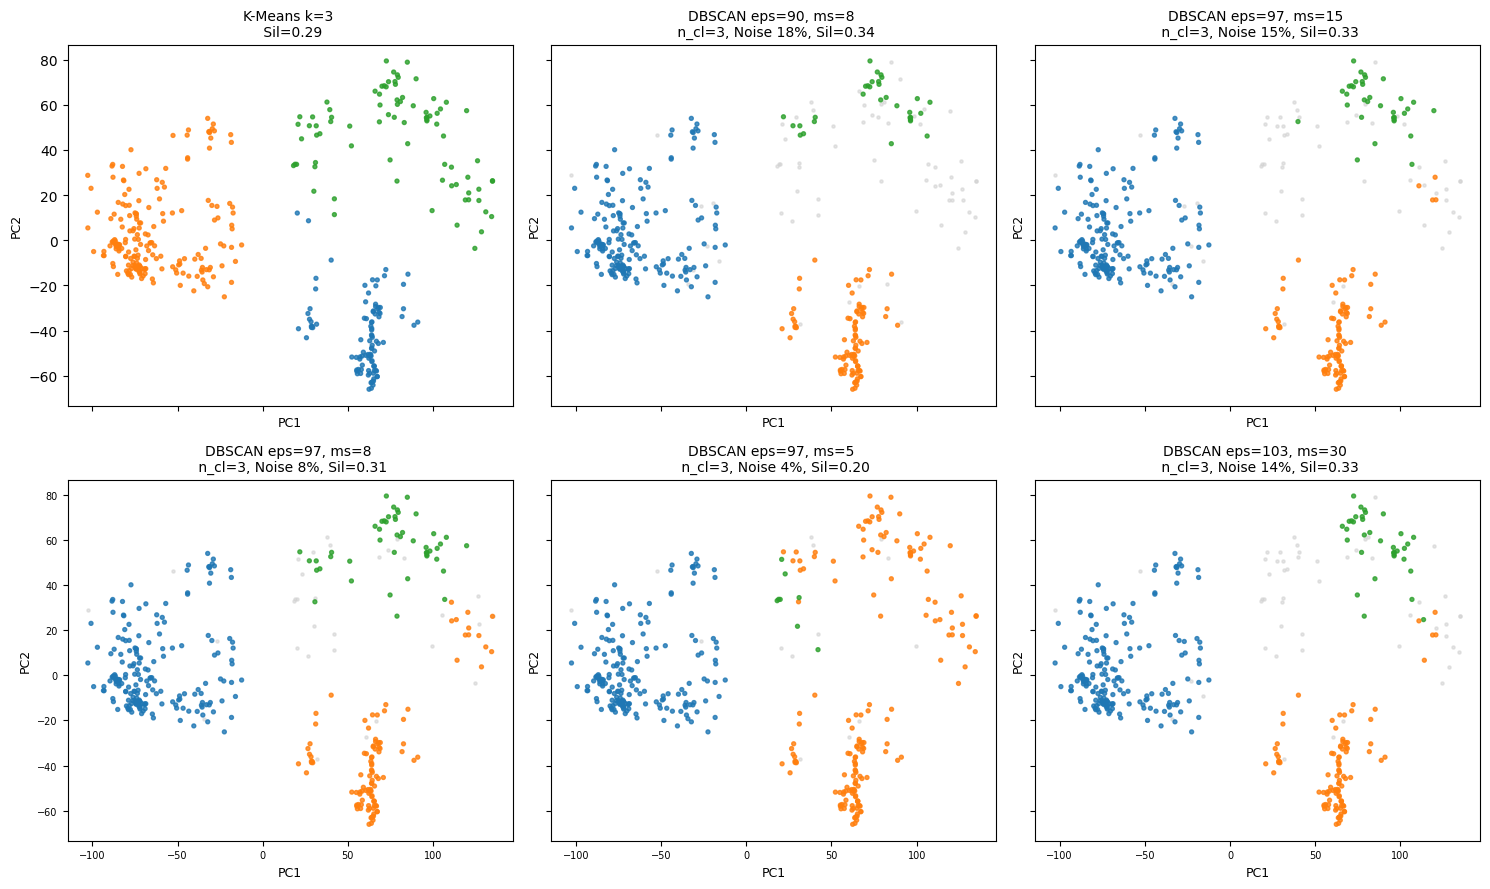

In [25]:
km3 = KMeans(n_clusters=3, n_init=50, random_state=0).fit_predict(X_reduced)

fig, axes = plt.subplots(2, 3, figsize=(15, 9), sharex=True, sharey=True, squeeze=False)  # fixed figsize
axes = axes.flatten()

axes[0].scatter(pca_c[:, 0], pca_c[:, 1], c=km3, cmap="tab10", vmin=0, vmax=9, s=8, alpha=0.8)
axes[0].set_title(f"K-Means k=3 \n Sil={silhouette_score(X_reduced, km3):.2f}", fontsize=10)
axes[0].set_xlabel("PC1", fontsize=9)
axes[0].set_ylabel("PC2", fontsize=9)

for ax, (e, ms) in zip(axes[1:], the_ones):
    db = DBSCAN(eps=e, min_samples=ms).fit_predict(X_reduced)
    mask = db != -1
    n_clusters = len(set(db[mask]))
    sil = silhouette_score(X_reduced[mask], db[mask]) if n_clusters >= 2 else np.nan

    ax.scatter(pca_c[~mask, 0], pca_c[~mask, 1], c="lightgrey", s=5, alpha=0.6)   # noise first, subtle
    ax.scatter(pca_c[mask, 0], pca_c[mask, 1], c=db[mask], cmap="tab10", vmin=0, vmax=9, s=8, alpha=0.8)
    ax.set_title(f"DBSCAN eps={e}, ms={ms} \n n_cl={n_clusters}, Noise {(~mask).mean():.0%}, Sil={sil:.2f}", fontsize=10)
    ax.set_xlabel("PC1", fontsize=9)
    ax.set_ylabel("PC2", fontsize=9)
    ax.tick_params(labelsize=7)

for ax in axes[1 + len(the_ones):]:   # hide any unused panels
    ax.set_visible(False)

plt.tight_layout()
plt.show()

In [26]:
N_SEQ = 2
e, ms = the_ones[0]
db = DBSCAN(eps=e, min_samples=ms).fit_predict(X_reduced)
CHOSEN_CLUSTER = 0

# !!! distance in X_reduced space
def get_seq(n_seq, e, ms, chosen_cluster):
    centers = np.stack([X_reduced[km3 == c].mean(axis=0) for c in sorted(set(km3))]) # cluster centers
    dist_c = np.linalg.norm(X_reduced - centers[km3], axis=1) # distances from each seq to corresponding cluster center
    # representative closest to center
    nearest_seq = {c: np.where(km3 == c)[0][dist_c[km3 == c].argmin()] for c in sorted(set(km3))}
    # print(nearest_seq)
    # print(np.where(db == -1))
    noise_pos = np.where(db == -1)[0]
    # print(np.argsort(dist_c[noise_pos]))
    outliers = noise_pos[np.argsort(dist_c[noise_pos])[::-1][:N_SEQ]]

    # one far from center; one near the center (Cluster 0)
    cluster_indices = np.where(km3 == chosen_cluster)[0]
    cluster_dist = dist_c[cluster_indices]

    nearest_pos = cluster_dist.argmin()
    farthest_pos = cluster_dist.argmax()

    nearest_in_cluster = cluster_indices[nearest_pos]
    farthest_in_cluster = cluster_indices[farthest_pos]
    cluster_pair = [nearest_in_cluster, farthest_in_cluster]

    return nearest_seq, outliers, cluster_pair
    
def load_uniterpolated(seq):
    row = df_seq.row(seq, named=True)
    start, end = row["start"], row["end"]

    seq = (
        lf
        .filter(
            pl.col("Time").is_between(start, end)
            & pl.col(EIN)
        )
        .select("Time", *features)
        .sort("Time")
        .collect(engine="streaming")
    )

    t = (
        (seq["Time"] - seq["Time"][0])
        .dt.total_milliseconds()
        .to_numpy()
        / 1000
    )

    return t, seq

nearest_seq, outliers, cluster_pair = get_seq(N_SEQ, e, ms, CHOSEN_CLUSTER)

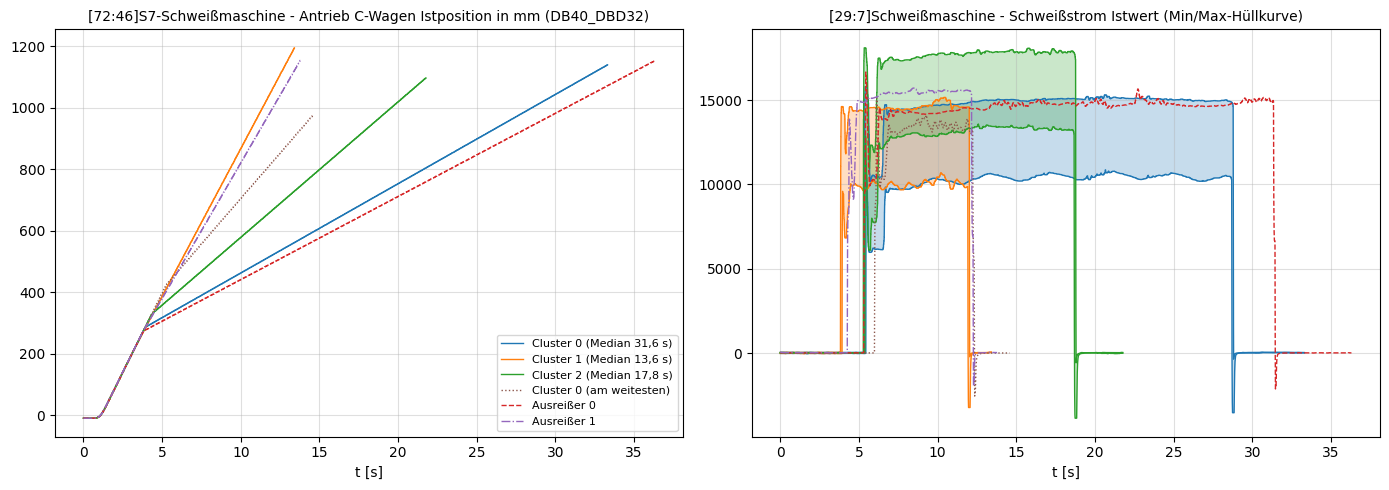

In [27]:
MM_WINDOW = 100  # window in samples (~0.1 s at 1 ms sampling)

dur = (df_seq["end"] - df_seq["start"]).dt.total_milliseconds().to_numpy() / 1000
loaded_rep = {c: load_uniterpolated(int(seq)) for c, seq in nearest_seq.items()}  # closest to cluster center

# (label, color, linestyle, (t, seq)); extra curves get their own colours so they are not mixed up with the clusters
curves = [
    (f"Cluster {c} (Median {np.median(dur[km3 == c]):.1f} s)".replace(".", ","), f"C{c}", "-", loaded)
    for c, loaded in loaded_rep.items()
]
curves.append((f"Cluster {CHOSEN_CLUSTER} (am weitesten)", "C5", ":", load_uniterpolated(int(cluster_pair[1]))))
curves += [
    (f"Ausreißer {i}", color, ls, load_uniterpolated(int(seq)))  # DBSCAN noise
    for i, (seq, color, ls) in enumerate(zip(outliers, ["C3", "C4"], ["--", "-."]))
]


def plot_cluster_feature(prefix, ax, suffix="", envelope=False, window=None, extras=True):
    feature = next(f for f in features if f.startswith(prefix))

    for label, color, ls, (t, seq) in curves:
        if ls != "-" and not extras:
            continue

        y = seq[feature].to_numpy().astype(float)

        if window:
            mask = (t >= window[0]) & (t <= window[1])
            t, y = t[mask], y[mask]

        if envelope:
            lo, hi = minimum_filter1d(y, MM_WINDOW), maximum_filter1d(y, MM_WINDOW)
            if ls == "-":
                ax.fill_between(t, lo, hi, color=color, alpha=0.25, linewidth=0)
                ax.plot(t, hi, color=color, lw=1, label=label)
                ax.plot(t, lo, color=color, lw=1)
            else:  # extra curves: only the middle of the envelope, otherwise it gets too crowded
                ax.plot(t, (lo + hi) / 2, color=color, linestyle=ls, lw=1, label=label)
        else:
            ax.plot(t, y, color=color, linestyle=ls, lw=1, label=label)

    ax.set_title(feature + suffix, fontsize=10)
    ax.set_xlabel("t [s]")
    ax.grid(alpha=0.4)


fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_cluster_feature("[72:46]", axes[0])
plot_cluster_feature("[29:7]", axes[1], suffix=" (Min/Max-Hüllkurve)", envelope=True)

axes[0].legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.savefig("assets/zeitreihen_vorschub_strom.png", dpi=150)
plt.show()

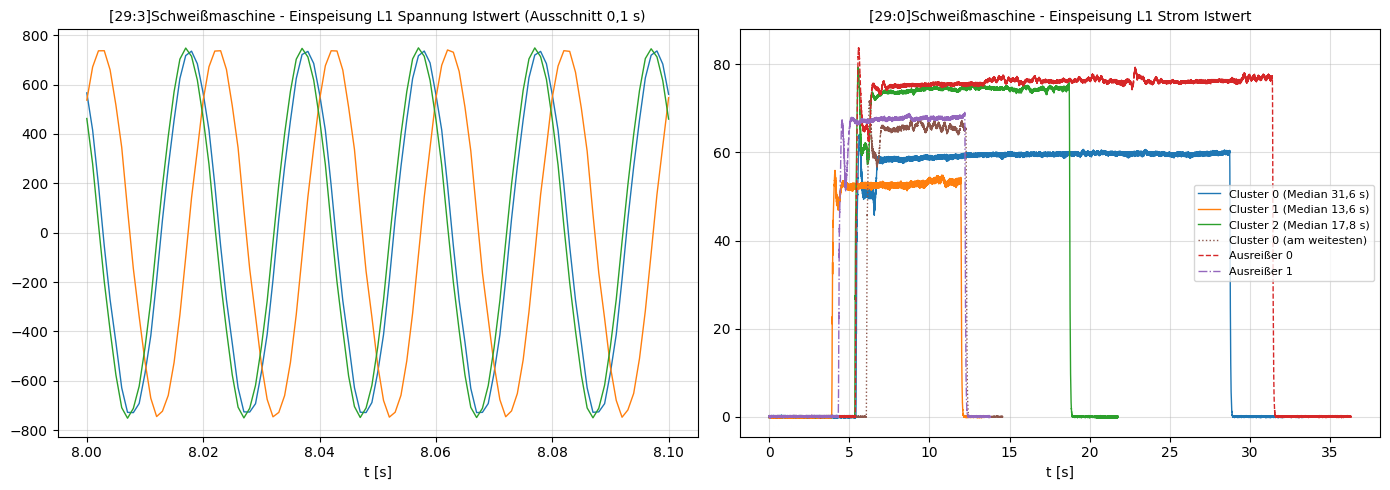

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_cluster_feature("[29:3]", axes[0], suffix=" (Ausschnitt 0,1 s)", window=(8.0, 8.1), extras=False)
plot_cluster_feature("[29:0]", axes[1])

axes[1].legend(fontsize=8, loc="center right")
plt.tight_layout()
plt.savefig("assets/einspeisung_spannung_strom.png", dpi=150)
plt.show()